# Stage 8 — Final Out-of-Sample Test Evaluation (2024–2025)

**Purpose.** One reproducible, leakage-free evaluation of the **frozen** Stage 4–7 pipeline on the held-out test split. Nothing is refitted, retrained, reselected, re-clustered or re-ranked. Stage 8 only reads frozen artifacts and writes to `results/stage8/`. It refuses to run a second time.

**Three kinds of evidence, kept apart throughout.**

| Label | What it is | Why it matters |
|---|---|---|
| **HISTORICAL** | Actual 2024–2025 market returns run through the frozen Stage 4 model and the Stage 3 risk engine. | Genuine out-of-sample evidence about the model and the portfolio. |
| **SIMULATION** | Frozen scenario paths replayed in the Stage 4 simulator with residual draws for seeds 90000–90499, starting from test-period anchor dates. | The simulator's dynamics do **not** depend on the anchor's market state. So for a *fixed* path, test anchors change only the observation, and these results are Monte Carlo robustness estimates, not historical test observations. |
| **POLICY** | The frozen Stage 5 PPO checkpoint acting on test-period market states. | This is the only RL-policy generalisation test the saved artifacts support. Q-learning tables were never saved, and retraining is not allowed. |

**Protocol.** The protocol is fixed before any test outcome is examined:
- test seeds and episode counts from `[training] test_seed = 90000, test_episodes = 500`;
- the coverage rule (nearest library scenario within the Stage 6 cluster cut 0.671 and in the same family);
- the target real weeks: every 5-day-limit breach episode plus the five worst distinct weeks.

Dependence among overlapping 5-day historical windows is handled by merging overlapping windows into distinct episodes and by computing intervals on non-overlapping windows only.

## 1. Project setup and dependency checks

In [1]:
# Colab: put the complete RS-RL folder (with data/ and results/) at /content/RS-RL, or set RSRL_ROOT, then run this cell.
import importlib.util
import os
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO = os.environ.get("RSRL_ROOT", "/content/RS-RL")
    if not os.path.exists(os.path.join(REPO, "pyproject.toml")):
        raise FileNotFoundError(f"RS-RL repository not found at {REPO}: upload or mount it there, or set RSRL_ROOT")
    os.chdir(REPO)
    if importlib.util.find_spec("rlstress") is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", ".[rl]"], check=True)   # README section 3.1
        sys.path.insert(0, os.path.join(REPO, "src"))
os.environ.setdefault("OMP_NUM_THREADS", "1")

import dataclasses
import hashlib
import json
import math
import time
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from scipy import stats

from rlstress.config import PROJECT_ROOT, load_config, resolve_path
from rlstress.data.storage import read_frame
from rlstress.features import rolling_volatility
from rlstress.final_evaluation import (kupiec_pof, merge_overlapping, nearest_scenario, newcombe_difference, non_overlapping,
                                       paired_bootstrap)
from rlstress.portfolio import Portfolio, calculate_portfolio_returns
from rlstress.risk import calculate_historical_cvar, calculate_historical_var
from rlstress.risk.drawdown import calculate_max_drawdown
from rlstress.rl.calibration import real_window_percentiles
from rlstress.rl.evaluation import diversity, evaluate_policy, summarize
from rlstress.rl.experiment import apply_overrides
from rlstress.rl.policies import RandomPolicy, scripted_decline_policy, zero_policy
from rlstress.rl.training import build_env, load_policy
from rlstress.scenario_library import (FACTOR_ORDER, classify_family, cumulative_feature, robustness_summary, wilson_interval)
from rlstress.scenario_recommender import (RecommenderConfig, eligibility, library_fingerprint, load_library, portfolio_profile,
                                           scenario_features, score, select_diverse, select_random, select_top, shortlist_fresh_metrics)
from rlstress.search import OpenLoopPolicy, evaluate_path
from rlstress.shocks import ShockModel
from rlstress.shocks.diagnostics import mahalanobis_calibration, simulated_vs_empirical
from rlstress.shocks.simulator import ShockSimulator
from rlstress.stress.historical_replay import evaluate_return_path

%matplotlib inline
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3dc", "grid.linewidth": 0.8})
VERSIONS = {p: version(p) for p in ("numpy", "pandas", "scipy", "gymnasium", "stable-baselines3", "torch", "matplotlib")}
print("Python", sys.version.split()[0], "| Colab" if IN_COLAB else "| local", "|", VERSIONS)
print("Project root:", PROJECT_ROOT)

Python 3.14.7 | local | {'numpy': '2.5.4', 'pandas': '3.0.6', 'scipy': '1.18.1', 'gymnasium': '1.4.0', 'stable-baselines3': '2.9.0', 'torch': '2.14.1', 'matplotlib': '3.11.2'}
Project root: RS-RL


In [2]:
# ---- Parameters (the preflight dry run substitutes EVAL_SPLIT = "validation" and a scratch OUT_DIR) ----
EVAL_SPLIT = "test"
OUT_DIR = PROJECT_ROOT / "results" / "stage8"
OVERWRITE = False                       # the final test runs once; an existing result is never replaced silently
RESULTS_PATH = OUT_DIR / "final_test_results.json"
if RESULTS_PATH.exists() and not OVERWRITE:
    raise FileExistsError(f"{RESULTS_PATH} exists: the final test has already been run; repeated test runs are not allowed")
PREFLIGHT = EVAL_SPLIT != "test"
print("Evaluation split:", EVAL_SPLIT, "(PREFLIGHT dry run, not a test result)" if PREFLIGHT else "(FINAL TEST)", "| output:", OUT_DIR)

Evaluation split: test (FINAL TEST) | output: RS-RL/results/stage8


## 2. Frozen-artifact manifest and checksum verification

In [3]:
CFG = load_config()
SIM, TRN = CFG.simulation, CFG.training
H, SEED, Q = SIM.horizon_days, SIM.seed, SIM.min_plausibility
STAGE4_MODEL = PROJECT_ROOT / SIM.output_dir / "shock_model.json"
PPO_RUN = PROJECT_ROOT / TRN.output_dir / "run_20261019T071324Z_main"        # the Stage 5 run whose selection.json the README reports
LIBRARY_PATH = PROJECT_ROOT / "results" / "stage6" / "scenario_library.json"
STAGE7_PATH = PROJECT_ROOT / "results" / "stage7" / "recommendations.json"
selection = json.loads((PPO_RUN / "selection.json").read_text())
CKPT_DIR = PROJECT_ROOT / Path(selection["selected_checkpoint"]).parent

# Hashes recorded when the protocol was frozen (2026-10-25), before any test-period outcome was computed.
FROZEN_EXPECTED = {
    "config/default.toml": "15924e725a6462922418476758114d923d7596dd2fd0e18356dc89afb0dbd882",
    "data/processed/features/consolidated_daily.csv": "e765acc019bb987f148c133db7f0b069059d0ca1a4ef7c81491d3e9e3b4bfdb8",
    "results/stage4/shock_model.json": "5fe13310b6f649f754cd94b6e97237f0fbba82c78a029605c907c5fa2e5e096a",
    "results/stage5/run_20261019T071324Z_main/shock_model.json": "5fe13310b6f649f754cd94b6e97237f0fbba82c78a029605c907c5fa2e5e096a",
    "results/stage5/run_20261019T071324Z_main/selection.json": "ea37db923e7c4f3465e57808754f8042b770c96859dd3fe8e650f164fb70fc83",
    "results/stage5/run_20261019T071324Z_main/training/thr_0.01/seed_0/best_model.zip": "319e51fc3e28c6fcc92b812ed49935720ec7c6cb63f024441d6ece1138948934",
    "results/stage5/run_20261019T071324Z_main/training/thr_0.01/seed_0/best_vecnormalize.pkl": "be2135cabb186deb76a50a452c4203ba9a4d3e9256d0c0b59067ab7467bc4909",
    "results/stage6/scenario_library.json": "47bb6c5d3049103b6bcb87232f259df61e77cf30833a6c5dd4eafae33633cca1",
    "results/stage7/recommendations.json": "045dfb911fa1897bbf6ef45d8dd6236bbae02eb5e927fc1822f7913da160db13",
}
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
manifest = pd.DataFrame([{"artifact": k, "sha256": sha(PROJECT_ROOT / k), "expected": v} for k, v in FROZEN_EXPECTED.items()])
manifest["match"] = manifest["sha256"] == manifest["expected"]
display(manifest.assign(sha256=manifest["sha256"].str[:16], expected=manifest["expected"].str[:16]).style.hide(axis="index"))
assert manifest["match"].all(), "a frozen artifact differs from its recorded checksum: stop"

# Everything Stage 8 must leave untouched: Stage 4-7 results, notebooks, source modules and the configuration.
def tree_hash(paths):
    h = hashlib.sha256()
    for p in sorted(paths):
        h.update(str(p.relative_to(PROJECT_ROOT)).encode()); h.update(p.read_bytes())
    return h.hexdigest()
SRC = PROJECT_ROOT / "src" / "rlstress"
PROTECTED = {
    **{f"results/{s}": sorted(p for p in (PROJECT_ROOT / "results" / s).rglob("*") if p.is_file()) for s in ("stage3", "stage4", "stage5", "stage6", "stage7")},
    "notebooks stage_4..7": [PROJECT_ROOT / f"stage_{i}.ipynb" for i in range(4, 8)],
    "source (Stage 3-7 modules)": sorted([*SRC.glob("env.py"), *SRC.glob("search.py"), *SRC.glob("scenario_library.py"), *SRC.glob("scenario_recommender.py"),
                                          *(SRC / "shocks").glob("*.py"), *(SRC / "rl").glob("*.py"), *(SRC / "risk").glob("*.py"),
                                          *(SRC / "stress").glob("*.py"), *(SRC / "portfolio").glob("*.py")]),
    "config": [PROJECT_ROOT / "config" / "default.toml"],
}
HASH_BEFORE = {k: tree_hash(v) for k, v in PROTECTED.items()}
print({k: len(v) for k, v in PROTECTED.items()})

artifact,sha256,expected,match
config/default.toml,15924e725a646292,15924e725a646292,True
data/processed/features/consolidated_daily.csv,e765acc019bb987f,e765acc019bb987f,True
results/stage4/shock_model.json,5fe13310b6f649f7,5fe13310b6f649f7,True
results/stage5/run_20261019T071324Z_main/shock_model.json,5fe13310b6f649f7,5fe13310b6f649f7,True
results/stage5/run_20261019T071324Z_main/selection.json,ea37db923e7c4f34,ea37db923e7c4f34,True
results/stage5/run_20261019T071324Z_main/training/thr_0.01/seed_0/best_model.zip,319e51fc3e28c6fc,319e51fc3e28c6fc,True
results/stage5/run_20261019T071324Z_main/training/thr_0.01/seed_0/best_vecnormalize.pkl,be2135cabb186deb,be2135cabb186deb,True
results/stage6/scenario_library.json,47bb6c5d3049103b,47bb6c5d3049103b,True
results/stage7/recommendations.json,045dfb911fa1897b,045dfb911fa1897b,True


{'results/stage3': 8, 'results/stage4': 4, 'results/stage5': 337, 'results/stage6': 1, 'results/stage7': 1, 'notebooks stage_4..7': 4, 'source (Stage 3-7 modules)': 31, 'config': 1}


## 3. Train / validation / test boundary verification

In [4]:
SPLITS = CFG.data.splits.as_dict()
source = read_frame(resolve_path(CFG.risk.returns_path, PROJECT_ROOT))
tickers = list(CFG.portfolio.tickers)
STOCK = [f"{t}_return" for t in tickers]
model = ShockModel.from_dict(json.loads(STAGE4_MODEL.read_text()))
FACT = list(model.factors)
assert tuple(FACT) == FACTOR_ORDER
needed = STOCK + FACT + list(SIM.state_columns)
rows = []
for name, (a, b) in SPLITS.items():
    w = source.loc[a:b, needed]
    rows.append({"split": name, "configured": f"{a} .. {b}", "first date": w.index.min().date(), "last date": w.index.max().date(),
                 "trading days": len(w), "rows with missing values": int(w.isna().any(axis=1).sum())})
bounds_tbl = pd.DataFrame(rows)
display(bounds_tbl.style.hide(axis="index"))
EVAL_START, EVAL_END = SPLITS[EVAL_SPLIT]
ev = source.loc[EVAL_START:EVAL_END]
split_summary = json.loads((PROJECT_ROOT / "data" / "processed" / "splits" / "split_summary.json").read_text())
assert pd.Timestamp(SPLITS["train"][1]) < pd.Timestamp(SPLITS["validation"][0]) and pd.Timestamp(SPLITS["validation"][1]) < pd.Timestamp(SPLITS["test"][0])
assert ev.index.min() >= pd.Timestamp(EVAL_START) and ev.index.max() <= pd.Timestamp(EVAL_END)
assert len(ev) == split_summary[EVAL_SPLIT]["n_rows"], "evaluation rows differ from the Stage 2 split summary"
assert not ev[needed].isna().any().any(), "missing values in the evaluation split"
TEST_FIRST, TEST_LAST, N_EVAL_DAYS = ev.index.min(), ev.index.max(), len(ev)
print(f"{EVAL_SPLIT}: {TEST_FIRST.date()} .. {TEST_LAST.date()}, {N_EVAL_DAYS} trading days; no missing factor, stock or state values")

split,configured,first date,last date,trading days,rows with missing values
train,2015-01-01 .. 2021-12-31,2015-01-02,2021-12-31,1763,16
validation,2022-01-01 .. 2023-12-31,2022-01-03,2023-12-29,501,0
test,2024-01-01 .. 2025-12-31,2024-01-02,2025-12-31,502,0


test: 2024-01-02 .. 2025-12-31, 502 trading days; no missing factor, stock or state values


## 4. Load the frozen Stage 4–7 artifacts
The Stage 4 shock model and the path-plausibility calibration were fitted on the training split. The Stage 5 PPO checkpoint and its observation normaliser are from training. The Stage 6 library and the Stage 7 recommendations are loaded as written. Recommendation weights, eligibility rules and shortlists are read from the Stage 7 output. As a reproducibility check (no test data involved), the frozen ranking is recomputed from the frozen artifacts.

In [5]:
library = load_library(LIBRARY_PATH)
lib_meta = library["metadata"]
L = {s["scenario_id"]: s for s in library["scenarios"]}
rec7 = json.loads(STAGE7_PATH.read_text())
assert rec7["schema_version"] == "stage7.v2" and rec7["provenance"]["library_sha256"] == library_fingerprint(LIBRARY_PATH)
RCFG = RecommenderConfig(**{k: v for k, v in rec7["config"].items()})
TOP_IDS = list(rec7["shortlists"]["highest_score"])
DIV_IDS = [d["scenario_id"] for d in rec7["shortlists"]["diversity_aware"]]
RANDOM_SEEDS = range(rec7["shortlists"]["random_seeds"][0], rec7["shortlists"]["random_seeds"][1] + 1)
ELIGIBLE = sorted(e["scenario_id"] for e in rec7["eligibility"] if e["eligible"])
PATHS = {sid: np.asarray(s["robust_action_path"], dtype=float) for sid, s in L.items()}
assert all(p.shape == (H, len(FACT)) for p in PATHS.values()), "incomplete five-day paths"
PATHS_SHA = hashlib.sha256(json.dumps({k: L[k]["robust_action_path"] for k in sorted(L)}).encode()).hexdigest()

# Reproduce the frozen Stage 7 ranking from frozen artifacts only (train-anchor deterministic replay, library evidence).
cfg_mean = dataclasses.replace(CFG, simulation=dataclasses.replace(SIM, residual_mode="mean"))
replay_env = build_env(cfg_mean, source, model, Q, "train")
anchor7 = replay_env.market_states.index[len(replay_env.market_states) // 2]
feat7 = eligibility(scenario_features(library, model.factor_sd, H), RCFG)
impacts7 = {r["scenario_id"]: float(evaluate_path(replay_env, np.asarray(r["padded_action_path"]), anchor7, SEED)["drawdown"]) for _, r in feat7.iterrows()}
train_returns = source.loc[SPLITS["train"][0]:SPLITS["train"][1], STOCK].rename(columns=lambda c: c.removesuffix("_return"))
sectors = {a.alias: a.sector for a in CFG.data.enabled_assets("stock")}
dd_limit = next(l.threshold for l in CFG.risk.limits if l.metric == "max_drawdown" and l.horizon_days == H)
profile = portfolio_profile("default", tickers, np.array(CFG.portfolio.weights, dtype=float), CFG.portfolio.initial_capital, model.raw_loadings,
                            model.factor_sd, sectors, train_returns, dd_limit)
S7 = score(feat7, profile, impacts7, RCFG)
ranking_reproduced = (select_top(S7, RCFG.top_k) == TOP_IDS and [d["scenario_id"] for d in select_diverse(S7, RCFG.top_k, RCFG)] == DIV_IDS
                      and sorted(S7.loc[S7["eligible"], "scenario_id"]) == ELIGIBLE)
frozen = {
    "risk limits": [dataclasses.asdict(l) for l in CFG.risk.limits if l.horizon_days == H],
    "plausibility threshold q": Q, "selected PPO threshold": selection["threshold"]["selected"], "selected PPO seed": selection["selected_seed"],
    "action bounds (12 model sd)": dict(zip(FACT, (12 * model.factor_sd).tolist())),
    "recommendation weights": RCFG.weights, "eligibility": {k: rec7["config"][k] for k in ("q", "min_screening_p_valid", "min_reporting_episodes", "max_p_implausible", "require_validated")},
    "diversity": {"lambda": RCFG.diversity_penalty, "tau": RCFG.similarity_scale, "k": RCFG.top_k},
    "shock model fit window": [model.fit_start, model.fit_end], "library scenarios": len(L), "eligible": len(ELIGIBLE),
}
print(json.dumps(frozen, indent=1, default=str)[:2500])
print("Highest-score shortlist:", TOP_IDS, "\nDiversity-aware shortlist:", DIV_IDS)
print("Frozen ranking reproduced from frozen artifacts:", ranking_reproduced)
assert ranking_reproduced

{
 "risk limits": [
  {
   "name": "stress_loss_5d",
   "metric": "cumulative_loss",
   "units": "fraction_of_initial_value",
   "horizon_days": 5,
   "threshold": 0.1,
   "breach_rule": ">=",
   "confidence": null,
   "description": "Cumulative portfolio loss over a 5-trading-day stress path"
  },
  {
   "name": "stress_drawdown_5d",
   "metric": "max_drawdown",
   "units": "fraction_of_peak_value",
   "horizon_days": 5,
   "threshold": 0.1,
   "breach_rule": ">=",
   "confidence": null,
   "description": "Peak-to-trough decline within a 5-trading-day stress path"
  }
 ],
 "plausibility threshold q": 0.01,
 "selected PPO threshold": 0.01,
 "selected PPO seed": 0,
 "action bounds (12 model sd)": {
  "SPY_return": 0.12667550557657425,
  "QQQ_return": 0.15960380604815844,
  "XLF_return": 0.16922785220932504,
  "XLE_return": 0.23355390155435574
 },
 "recommendation weights": {
  "relevance": 0.25,
  "impact": 0.25,
  "plausibility": 0.25,
  "robustness": 0.25
 },
 "eligibility": {
  "q": 


Highest-score shortlist: ['S6-cb7bea96', 'S6-0b517d5c', 'S6-57e21a76', 'S6-b0972d80', 'S6-5d0455b6'] 
Diversity-aware shortlist: ['S6-cb7bea96', 'S6-0b517d5c', 'S6-b0972d80', 'S6-b13030ae', 'S6-57e21a76']
Frozen ranking reproduced from frozen artifacts: True


## 5. Test-data integrity and look-ahead checks
* No frozen artifact may have used test observations: the model fit window, the plausibility calibration, state standardisation, PPO training anchors, Stage 6 screening and reporting, and the Stage 7 evaluation are all checked.
* Each test anchor's market state (VIX close, trailing 20-day SPY volatility) must be computable from data **up to that date**. This is verified by recomputing the volatility on data truncated at the anchor.
* Test seeds must be disjoint from every seed range used upstream.

In [6]:
TEST_SEEDS = range(TRN.test_seed, TRN.test_seed + TRN.test_episodes)          # [training] test_seed / test_episodes, fixed before Stage 5
UPSTREAM_SEEDS = {"Stage 5/6 screening": range(10_000, 10_200), "Stage 5/6 reporting": range(20_000, 20_500), "Stage 5 PPO / Stage 7 fresh": range(30_000, 30_500),
                  "Stage 5 PPO reporting set 3": range(40_000, 40_500), "Q-learning training (train)": range(43, 45 + 20_000),
                  "discrete MC draws (train)": range(50_000, 50_010), "DP data (train)": range(60_000, 80_000), "Q harvest (train)": range(70_000, 70_200)}
seed_overlap = {k: len(set(TEST_SEEDS) & set(r)) for k, r in UPSTREAM_SEEDS.items()}
eval_env = build_env(CFG, source, model, Q, EVAL_SPLIT)                     # sampled residuals, evaluation-split anchors (as Stage 6/7)
anchors = eval_env.market_states.index
spy = source["SPY_return"]
vol_cols = [c for c in SIM.state_columns if "vol_ann" in c]
lookahead_max_err = 0.0
for a in anchors[:: max(1, len(anchors) // 25)].append(anchors[-1:]):
    past = spy.loc[:a]
    for col in vol_cols:
        w = int(col.split("_")[-1].removesuffix("d"))
        recomputed = rolling_volatility(past, w, math.ceil(CFG.data.features.min_obs_fraction * w), CFG.data.features.annualization_days).iloc[-1]
        lookahead_max_err = max(lookahead_max_err, abs(recomputed - source.loc[a, col]))
leak = {
    "shock model fitted inside train": pd.Timestamp(model.fit_end) <= pd.Timestamp(SPLITS["train"][1]) and pd.Timestamp(model.fit_start) >= pd.Timestamp(SPLITS["train"][0]),
    "plausibility calibration from the fitted (train) model": set(model.path_calibration) >= {str(t) for t in range(1, H + 1)},
    "state standardisation window = train": SIM.fit_window == "train",
    "PPO trained on train anchors": SIM.anchor_window == "train",
    "Stage 5 selection used no test data": selection["uses_test_data"] is False,
    "Stage 6 library: validation anchors, no test split": lib_meta["selection_rule"]["test_split_used"] is False and lib_meta["selection_rule"]["anchors"] == "validation split only",
    "Stage 7: no test split": rec7["provenance"]["test_split_used"] is False,
    "evaluation anchors inside the evaluation split": anchors.min() >= TEST_FIRST and anchors.max() <= TEST_LAST,
    "anchor states use only past data (recomputed)": lookahead_max_err < 1e-10,
    "test seeds disjoint from all upstream seeds": not any(seed_overlap.values()),
}
display(pd.DataFrame([{"check": k, "ok": v} for k, v in leak.items()]).style.hide(axis="index"))
print(f"{len(anchors)} evaluation anchors {anchors.min().date()} .. {anchors.max().date()}; max |recomputed - stored| state = {lookahead_max_err:.1e}")
assert all(leak.values())

check,ok
shock model fitted inside train,True
plausibility calibration from the fitted (train) model,True
state standardisation window = train,True
PPO trained on train anchors,True
Stage 5 selection used no test data,True
"Stage 6 library: validation anchors, no test split",True
Stage 7: no test split,True
evaluation anchors inside the evaluation split,True
anchor states use only past data (recomputed),True
test seeds disjoint from all upstream seeds,True


502 evaluation anchors 2024-01-02 .. 2025-12-31; max |recomputed - stored| state = 1.5e-15


## 6. Stage 4 — frozen risk model on actual market data (HISTORICAL)
Every quantity uses the frozen train-fitted model and the Stage 3 risk engine on **actual** returns, for the validation and test periods side by side (train shown for reference). These are statements about the model's fit to history. The real market paths were not generated by the shock model.

In [7]:
pf = Portfolio.from_config(CFG.portfolio, universe=tickers)
CAP = CFG.portfolio.initial_capital
PERIODS = ["train", "validation", EVAL_SPLIT] if EVAL_SPLIT != "validation" else ["train", "validation"]
win = lambda split: source.loc[SPLITS[split][0]:SPLITS[split][1]]

# (a) out-of-sample factor-model fit: frozen a + B f
fit_rows = []
for split in PERIODS:
    w = win(split)[FACT + STOCK].dropna()
    r, f = w[STOCK].to_numpy(), w[FACT].to_numpy()
    e = r - (model.raw_intercept + f @ model.raw_loadings.T)
    for i, t in enumerate(tickers):
        fit_rows.append({"period": split, "ticker": t, "R2": 1 - (e[:, i] ** 2).sum() / ((r[:, i] - r[:, i].mean()) ** 2).sum(), "residual sd": e[:, i].std(ddof=1), "days": len(w)})
fit = pd.DataFrame(fit_rows).pivot(index="ticker", columns="period", values=["R2", "residual sd"])
fit[("residual sd", f"{EVAL_SPLIT} / train")] = fit[("residual sd", EVAL_SPLIT)] / fit[("residual sd", "train")]
display(fit.style.format("{:.3f}").set_caption("Frozen factor model: R² and residual sd by period (R² outside train = out-of-sample)"))

# (b) daily factor-distribution calibration (plausibility model); Wilson CIs treat days as independent (see limitations)
cal_rows = []
for split in PERIODS:
    c = mahalanobis_calibration(model, win(split)[FACT].dropna(), "plausibility")
    for t in c["tail_rates"]:
        k = round(t["empirical_share"] * c["n_days"]); lo, hi = wilson_interval(k, c["n_days"])
        cal_rows.append({"period": split, "nominal tail": t["level"], "days": c["n_days"], "days in tail": k, "share": t["empirical_share"], "95% CI": f"[{lo:.3%}, {hi:.3%}]"})
calib = pd.DataFrame(cal_rows)
display(calib.style.hide(axis="index").format({"nominal tail": "{:.1%}", "share": "{:.2%}"}).set_caption("Share of actual days beyond the model's daily tail level"))

# (c) actual 5-day factor windows rejected as implausible at q (overlapping windows; non-overlapping subsample for the CI)
plaus_rows, real_pct = [], {}
for split in PERIODS:
    pct = real_window_percentiles(model, source, *SPLITS[split], H)
    real_pct[split] = pct
    rej = (pct < Q).to_numpy()
    no = non_overlapping(len(pct), H)
    k, n = int(rej[no].sum()), len(no)
    lo, hi = wilson_interval(k, n)
    plaus_rows.append({"period": split, "windows (overlapping)": len(pct), "rejected (overlapping)": int(rej.sum()), "distinct rejected episodes": len(merge_overlapping(np.flatnonzero(rej), H)),
                       "non-overlapping windows": n, "rejected (non-overlapping)": k, "share (non-overlapping)": k / n, "95% CI": f"[{lo:.2%}, {hi:.2%}]", "expected share": Q})
plaus_hist = pd.DataFrame(plaus_rows)
display(plaus_hist.style.hide(axis="index").format({"share (non-overlapping)": "{:.2%}", "expected share": "{:.0%}"}).set_caption(f"Actual 5-day factor windows less plausible than q = {Q}"))

period,nominal tail,days,days in tail,share,95% CI
train,5.0%,1762,63,3.58%,"[2.805%, 4.548%]"
train,1.0%,1762,12,0.68%,"[0.390%, 1.187%]"
train,0.1%,1762,0,0.00%,"[0.000%, 0.218%]"
validation,5.0%,501,24,4.79%,"[3.240%, 7.029%]"
validation,1.0%,501,0,0.00%,"[0.000%, 0.761%]"
validation,0.1%,501,0,0.00%,"[0.000%, 0.761%]"
test,5.0%,502,7,1.39%,"[0.677%, 2.850%]"
test,1.0%,502,1,0.20%,"[0.035%, 1.120%]"
test,0.1%,502,0,0.00%,"[0.000%, 0.759%]"


period,windows (overlapping),rejected (overlapping),distinct rejected episodes,non-overlapping windows,rejected (non-overlapping),share (non-overlapping),95% CI,expected share
train,1758,17,2,352,3,0.85%,"[0.29%, 2.48%]",1%
validation,497,0,0,100,0,0.00%,"[0.00%, 3.70%]",1%
test,498,0,0,100,0,0.00%,"[0.00%, 3.70%]",1%


In [8]:
# (d) model-simulated vs actual daily stock and portfolio tails (unconditional model draws, Stage 4 diagnostic)
simulator = ShockSimulator(model, SIM)
sve_rows, sve_port = [], []
for split in PERIODS[1:]:
    stocks = win(split)[STOCK].dropna().rename(columns=lambda c: c.removesuffix("_return"))
    d = simulated_vs_empirical(simulator, stocks, pf.weights, CAP, SIM.diagnostic_simulations, SEED)
    sve_rows += [{"period": split, **s} for s in d["per_stock"]]
    sve_port += [{"period": split, **p, "portfolio sd empirical": d["portfolio_sd_empirical"], "portfolio sd model": d["portfolio_sd_model"]} for p in d["portfolio"]]
sve = pd.DataFrame(sve_rows)
sve["sd ratio (actual / model)"] = sve["sd_empirical"] / sve["sd_model"]
sve["q01 ratio (actual / model)"] = sve["q01_empirical"] / sve["q01_model"]
display(sve.pivot(index="ticker", columns="period", values=["sd ratio (actual / model)", "q01 ratio (actual / model)"]).style.format("{:.2f}")
        .set_caption(f"Actual vs model daily stock tails ({SIM.diagnostic_simulations:,} simulated days, seed {SEED})"))
display(pd.DataFrame(sve_port).style.hide(axis="index").format({c: "{:.2%}" for c in ["var_empirical", "var_model", "cvar_empirical", "cvar_model", "portfolio sd empirical", "portfolio sd model"]}))

# (e) historical portfolio risk with the Stage 3 engine: VaR/CVaR estimated on train, exceedances out of sample
rp = {s: calculate_portfolio_returns(win(s)[STOCK].dropna().rename(columns=lambda c: c.removesuffix("_return")), pf.weights) for s in PERIODS}
var_rows = []
for conf in CFG.risk.confidence_levels:
    v = calculate_historical_var(rp["train"], conf, CAP, CFG.risk.min_observations).var_pct
    cv = calculate_historical_cvar(rp["train"], conf, CAP, CFG.risk.min_observations).cvar_pct
    for s in PERIODS[1:]:
        kp = kupiec_pof(int((rp[s] < -v).sum()), len(rp[s]), 1 - conf)
        var_rows.append({"confidence": conf, "period": s, "train VaR": v, "train CVaR": cv, "days": kp["n"], "exceedances": kp["exceedances"], "expected": kp["expected"],
                         "rate": kp["rate"], "Kupiec p-value": kp["p_value"], f"{s} VaR (descriptive)": calculate_historical_var(rp[s], conf, CAP).var_pct,
                         "mean loss on exceedance days": float(-rp[s][rp[s] < -v].mean()) if (rp[s] < -v).any() else np.nan})
var_bt = pd.DataFrame(var_rows)
display(var_bt.style.hide(axis="index").format({c: "{:.2%}" for c in var_bt.columns if c not in ("confidence", "period", "days", "exceedances", "expected", "Kupiec p-value")} | {"expected": "{:.1f}", "Kupiec p-value": "{:.3f}"}, na_rep="—")
        .set_caption("1-day VaR backtest: train-estimated VaR, out-of-sample exceedances (Kupiec unconditional coverage)"))
perf = []
for s in PERIODS:
    vals = CAP * (1 + rp[s]).cumprod()
    dd = calculate_max_drawdown(vals)
    perf.append({"period": s, "days": len(rp[s]), "total return": float(vals.iloc[-1] / CAP - 1), "annual vol": float(rp[s].std(ddof=1) * np.sqrt(CFG.risk.annualization_days)),
                 "max drawdown": dd.max_drawdown, "trough": dd.trough_date, "worst day": float(rp[s].min()), "worst day date": rp[s].idxmin().date()})
perf = pd.DataFrame(perf)
display(perf.style.hide(axis="index").format({"total return": "{:.1%}", "annual vol": "{:.1%}", "max drawdown": "{:.1%}", "worst day": "{:.2%}"}))

period,confidence,var_empirical,var_model,cvar_empirical,cvar_model,portfolio sd empirical,portfolio sd model
validation,0.950000,1.93%,1.77%,2.74%,2.66%,1.26%,1.23%
validation,0.990000,3.38%,3.11%,3.86%,4.34%,1.26%,1.23%
test,0.950000,1.32%,1.77%,2.20%,2.66%,1.00%,1.23%
test,0.990000,2.53%,3.11%,3.94%,4.34%,1.00%,1.23%


confidence,period,train VaR,train CVaR,days,exceedances,expected,rate,Kupiec p-value,validation VaR (descriptive),mean loss on exceedance days,test VaR (descriptive)
0.950000,validation,1.86%,3.06%,501,27,25.1,5.39%,0.693,1.93%,2.68%,—
0.950000,test,1.86%,3.06%,502,12,25.1,2.39%,0.003,—,2.94%,1.32%
0.990000,validation,3.68%,5.16%,501,4,5.0,0.80%,0.638,3.38%,3.96%,—
0.990000,test,3.68%,5.16%,502,2,5.0,0.40%,0.123,—,5.48%,2.53%


period,days,total return,annual vol,max drawdown,trough,worst day,worst day date
train,1762,399.4%,20.1%,-30.6%,2020-03-23,-11.07%,2020-03-16
validation,501,35.5%,20.0%,-21.7%,2022-09-30,-4.44%,2022-09-13
test,502,90.2%,15.8%,-19.2%,2025-04-08,-5.93%,2025-04-04


In [9]:
# (f) actual 5-day windows against the 5-day risk limits (Stage 3 evaluate_return_path), with factor paths for coverage analysis
LIM5 = [l for l in CFG.risk.limits if l.horizon_days == H]
BOUNDS = 12 * model.factor_sd                                            # action units: factor return / (12 model sd), Stage 4
def real_windows(split):
    w = source.loc[:SPLITS[split][1], STOCK + FACT]
    first = w.index.get_loc(win(split).index[0])
    out = []
    for i in range(first, len(w) - H + 1):
        path = w.iloc[i:i + H]
        res = evaluate_return_path(pf, path[STOCK].rename(columns=lambda c: c.removesuffix("_return")), w.index[i - 1], LIM5)
        vals = np.array(list(res.value_path.values()))
        run_dd = 1 - vals / np.maximum.accumulate(vals)
        hit = np.flatnonzero(run_dd[1:] >= dd_limit - CFG.risk.comparison_tolerance)
        days = int(hit[0] + 1) if len(hit) else H
        actions = path[FACT].to_numpy() / BOUNDS
        out.append({"start": w.index[i], "end": w.index[i + H - 1], "loss": res.loss_pct, "drawdown": -res.max_drawdown,
                    **{f"breach {r.limit_name}": r.breached for r in res.limit_results}, "breached": res.breached,
                    "days to breach": days if len(hit) else None, "plausibility rank": real_pct[split].get(w.index[i], np.nan),
                    "family": classify_family(actions[:days]), "feature": cumulative_feature(actions, days), "actions": actions})
    return pd.DataFrame(out)
RW = {s: real_windows(s) for s in PERIODS[1:]}
lim_rows = []
for s, df in RW.items():
    pos = np.flatnonzero(df["breached"].to_numpy())
    eps = merge_overlapping(pos, H)
    no = non_overlapping(len(df), H)
    shares = [df["breached"].to_numpy()[non_overlapping(len(df), H, o)].mean() for o in range(H)]
    k, n = int(df["breached"].to_numpy()[no].sum()), len(no)
    lo, hi = wilson_interval(k, n)
    lim_rows.append({"period": s, "5-day windows": len(df), "breach windows (overlapping)": len(pos), "distinct breach episodes": len(eps),
                     "non-overlapping windows": n, "breaches (non-overlapping)": k, "share": k / n, "95% CI": f"[{lo:.2%}, {hi:.2%}]",
                     "share range over 5 offsets": f"{min(shares):.2%} – {max(shares):.2%}", "worst 5-day drawdown": df["drawdown"].max(),
                     "worst window start": df.loc[df["drawdown"].idxmax(), "start"].date(), "worst 5-day loss": df["loss"].max(),
                     "loss-limit breaches": int(df["breach stress_loss_5d"].sum()), "drawdown-limit breaches": int(df["breach stress_drawdown_5d"].sum())})
limit_hist = pd.DataFrame(lim_rows)
display(limit_hist.style.hide(axis="index").format({"share": "{:.2%}", "worst 5-day drawdown": "{:.2%}", "worst 5-day loss": "{:.2%}"})
        .set_caption("Actual 5-day windows vs the 5-day limits (distinct episodes merge overlapping windows; CI on non-overlapping windows)"))

# (g) historical vs simulated 5-day tail: unconditional model paths (5 i.i.d. model days) vs actual windows
rng = np.random.default_rng(SEED)
N_PATHS = 20_000
_, sim_days = simulator.sample_days(rng, N_PATHS * H)
sim_r = (sim_days @ pf.weights[list(model.tickers)].to_numpy()).reshape(N_PATHS, H)
sim_vals = np.cumprod(1 + sim_r, axis=1)
sim_dd = (1 - sim_vals / np.maximum.accumulate(np.hstack([np.ones((N_PATHS, 1)), sim_vals]), axis=1)[:, 1:]).max(axis=1)
tail_rows = [{"sample": "model (unconditional, 20,000 paths)", "5-day drawdown p95": np.quantile(sim_dd, 0.95), "p99": np.quantile(sim_dd, 0.99),
              "share >= limit": float((sim_dd >= dd_limit).mean())}]
for s, df in RW.items():
    tail_rows.append({"sample": f"actual {s} (overlapping windows)", "5-day drawdown p95": df["drawdown"].quantile(0.95), "p99": df["drawdown"].quantile(0.99),
                      "share >= limit": float((df["drawdown"] >= dd_limit).mean())})
tail_tbl = pd.DataFrame(tail_rows)
display(tail_tbl.style.hide(axis="index").format({c: "{:.2%}" for c in tail_tbl.columns if c != "sample"}))

period,5-day windows,breach windows (overlapping),distinct breach episodes,non-overlapping windows,breaches (non-overlapping),share,95% CI,share range over 5 offsets,worst 5-day drawdown,worst window start,worst 5-day loss,loss-limit breaches,drawdown-limit breaches
validation,497,0,0,100,0,0.00%,"[0.00%, 3.70%]",0.00% – 0.00%,9.34%,2022-06-08,9.34%,0,0
test,498,4,1,100,0,0.00%,"[0.00%, 3.70%]",0.00% – 1.01%,12.56%,2025-04-03,12.03%,2,4


sample,5-day drawdown p95,p99,share >= limit
"model (unconditional, 20,000 paths)",4.54%,6.64%,0.11%
actual validation (overlapping windows),5.19%,7.12%,0.00%
actual test (overlapping windows),3.60%,5.74%,0.80%


## 7. Stage 5 — frozen PPO policy on test-period states (POLICY), and scenario replay
**Policy generalisation.** The Stage 5 selected checkpoint (run `_main`, q = 0.01, seed 0, `best_model.zip` with its frozen `VecNormalize` statistics) acts deterministically on the observation, which includes the standardised market state of the test anchor. It is evaluated with the zero-action, scripted-decline and random baselines on the same 500 test seeds, so episode *i* has the same anchor and residual RNG for every policy. This uses the reward and termination rules of the run's configuration snapshot. It reproduces the existing `final_test` protocol but writes nothing into the Stage 5 run directory.

**Q-learning.** Tabular Q-tables were not saved by Stages 5 and 6, and retraining is not allowed. Q-learning policy generalisation is therefore **not tested**. Its discovered paths enter Section 8 as fixed scenarios, and a fixed replay is not policy generalisation.

In [10]:
run_meta = json.loads((PPO_RUN / "run_meta.json").read_text())
run_cfg = apply_overrides(load_config(PPO_RUN / "config.toml"), run_meta.get("overrides", {}))
q_sel, seed_sel = selection["threshold"]["selected"], selection["selected_seed"]
run_model = ShockModel.from_dict(json.loads((PPO_RUN / "shock_model.json").read_text()))
ppo_env = build_env(run_cfg, source, run_model, q_sel, EVAL_SPLIT)
k_f = ppo_env.simulator.model.k
policies = [zero_policy(k_f), scripted_decline_policy(k_f, run_cfg.training.scripted_action), RandomPolicy(k_f, run_cfg.training.random_baseline_seed_offset),
            load_policy(CKPT_DIR, ppo_env, "best", name=f"ppo_seed_{seed_sel}")]
policy_records, policy_failures = {}, {}
t0 = time.perf_counter()
for pol in policies:
    try:
        policy_records[pol.name] = evaluate_policy(ppo_env, pol, TEST_SEEDS)
    except Exception as exc:                                          # recorded, never silently dropped
        policy_failures[pol.name] = repr(exc)
ppo_runtime = time.perf_counter() - t0
val_metrics = json.loads((PPO_RUN / "validation" / "metrics.json").read_text())[str(q_sel)]
pol_rows = []
for name, recs in policy_records.items():
    s = summarize(recs)
    v = val_metrics[name]["pooled"]
    kt, nt = round(s["valid_breach_rate"] * s["n_episodes"]), s["n_episodes"]
    kv, nv = round(v["valid_breach_rate"] * v["n_episodes"]), v["n_episodes"]
    d, dlo, dhi = newcombe_difference(kt, nt, kv, nv)
    lo, hi = wilson_interval(kt, nt)
    pol_rows.append({"policy": name, f"{EVAL_SPLIT} episodes": nt, f"{EVAL_SPLIT} valid breach": s["valid_breach_rate"], "95% CI": f"[{lo:.1%}, {hi:.1%}]",
                     "validation valid breach (1,500 eps)": v["valid_breach_rate"], "difference": d, "difference 95% CI": f"[{dlo:+.1%}, {dhi:+.1%}]",
                     f"{EVAL_SPLIT} any breach": s["breach_rate"], "validation any breach": v["breach_rate"],
                     f"{EVAL_SPLIT} implausible breach": s["implausible_breach_rate"], "validation implausible breach": v["implausible_breach_rate"],
                     f"{EVAL_SPLIT} invalid (failed) episodes": round(s["invalid_rate"] * nt), "mean drawdown at breach": s["severity_breaches"]["mean"],
                     "mean episode return": s["episode_return"]["mean"], "validation mean return": v["episode_return"]["mean"],
                     "anchors inside split": all(TEST_FIRST <= pd.Timestamp(r.anchor_date) <= TEST_LAST for r in recs)})
policy_tbl = pd.DataFrame(pol_rows)
display(policy_tbl.style.hide(axis="index").format({c: "{:.1%}" for c in policy_tbl.columns if "breach" in c and "CI" not in c} | {"difference": "{:+.1%}", "mean drawdown at breach": "{:.2%}",
        "mean episode return": "{:.2f}", "validation mean return": "{:.2f}"}, na_rep="—").set_caption(f"Frozen policies on {EVAL_SPLIT} anchors, seeds {TEST_SEEDS.start}-{TEST_SEEDS.stop - 1} (q = {q_sel})"))
ppo_div = diversity(policy_records[f"ppo_seed_{seed_sel}"], run_model.factor_sd, run_model.factors) if f"ppo_seed_{seed_sel}" in policy_records else None
print(f"Policy evaluation: {len(policy_records)} policies x {len(TEST_SEEDS)} episodes in {ppo_runtime:.1f}s; failures: {policy_failures or 'none'}")

policy,test episodes,test valid breach,95% CI,"validation valid breach (1,500 eps)",difference,difference 95% CI,test any breach,validation any breach,test implausible breach,validation implausible breach,test invalid (failed) episodes,mean drawdown at breach,mean episode return,validation mean return,anchors inside split
zero_action,500,0.0%,"[0.0%, 0.8%]",0.0%,+0.0%,"[-0.3%, +0.8%]",0.0%,0.0%,0.0%,0.0%,0,—,-0.03,-0.03,True
scripted_moderate_decline,500,89.4%,"[86.4%, 91.8%]",88.5%,+0.9%,"[-2.4%, +3.9%]",89.4%,88.5%,0.0%,0.0%,0,11.02%,7.63,7.54,True
random_action,500,0.0%,"[0.0%, 0.8%]",0.0%,+0.0%,"[-0.3%, +0.8%]",50.0%,51.5%,50.0%,51.5%,0,13.16%,-8.28,-8.24,True
ppo_seed_0,500,22.8%,"[19.3%, 26.7%]",25.5%,-2.7%,"[-6.8%, +1.8%]",99.8%,100.0%,77.0%,74.5%,0,11.32%,1.31,1.57,True


Policy evaluation: 4 policies x 500 episodes in 20.8s; failures: none


## 8. Stage 6 — frozen scenario library (SIMULATION + HISTORICAL coverage)
**Replay (SIMULATION).** Each of the 16 scenarios' complete five-day `robust_action_path` is replayed open-loop with sampled residuals on the 500 test seeds. All scenarios use the same seeds, so they are compared under common random numbers. Because the simulator ignores the anchor's market state, these are simulation-based robustness estimates. Validation-to-test differences measure Monte Carlo variation, not a change in market regime. A deterministic replay on a test anchor must reproduce the Stage 6 deterministic values exactly, and this demonstrates the anchor-independence.

**Coverage (HISTORICAL).** Each actual test-period 5-day window is converted to action units (factor return / 12 model sd), cut at its breach day, and classified with the Stage 6 family rules. Each target real week — every distinct limit-breach episode (its worst window) plus the five worst distinct weeks — is matched to its nearest library scenario in the Stage 6 cumulative-path space. A week counts as **covered** if that scenario is within the cluster cut τ = 0.671 *and* has the same family. The rule was fixed in advance.

In [11]:
OBS = {n: i for i, n in enumerate(eval_env.observation_names)}
SIDS = sorted(L)
rep_records, replay_failures = {}, {}
t0 = time.perf_counter()
for sid in SIDS:
    try:
        rep_records[sid] = evaluate_policy(eval_env, OpenLoopPolicy(PATHS[sid], OBS, sid), TEST_SEEDS)
    except Exception as exc:
        replay_failures[sid] = repr(exc)
replay_runtime = time.perf_counter() - t0
assert not replay_failures, f"replay failures: {replay_failures}"
M = {key: np.array([[getattr(r, key) for r in rep_records[sid]] for sid in SIDS], dtype=float).T for key in ("valid_breach", "implausible_breach", "breached")}
invalid_eps = {sid: sum(r.termination == "invalid" for r in rep_records[sid]) for sid in SIDS}
fresh7 = {r["scenario_id"]: r for r in rec7["independent_evaluation"]["per_scenario"]}
rows = []
for j, sid in enumerate(SIDS):
    s = robustness_summary(rep_records[sid]); s6 = L[sid]
    kt, n = int(M["valid_breach"][:, j].sum()), len(TEST_SEEDS)
    d_rep = newcombe_difference(kt, n, round(s6["p_valid"] * s6["reporting_episodes"]), s6["reporting_episodes"])
    f = fresh7.get(sid)
    d_fr = newcombe_difference(kt, n, round(f["p_valid"] * f["episodes"]), f["episodes"]) if f else (np.nan, np.nan, np.nan)
    rows.append({"scenario_id": sid, "status": s6["status"], "eligible": sid in ELIGIBLE, "family": s6["family"], "cluster": s6["cluster"],
                 "methods": "; ".join(s6["discovery_methods"]), "episodes": s["episodes"], "invalid episodes": invalid_eps[sid],
                 "P(valid)": s["p_valid"], "CI low": s["p_valid_ci95"][0], "CI high": s["p_valid_ci95"][1], "P(implausible)": s["p_implausible"],
                 "P(any breach)": s["p_any_breach"], "drawdown at breach": s["mean_drawdown_at_breach"], "breach day": s["mean_breach_day"],
                 "median valid rank": s["median_valid_rank"], "val reporting P(valid)": s6["p_valid"], "diff vs reporting": d_rep[0],
                 "diff vs reporting CI": f"[{d_rep[1]:+.1%}, {d_rep[2]:+.1%}]", "val fresh P(valid)": f["p_valid"] if f else np.nan,
                 "diff vs fresh": d_fr[0], "diff vs fresh CI": f"[{d_fr[1]:+.1%}, {d_fr[2]:+.1%}]" if f else "—",
                 "val drawdown at breach": s6["mean_drawdown_at_breach"]})
lib_test = pd.DataFrame(rows).set_index("scenario_id")
display(lib_test.drop(columns=["methods"]).style.format({c: "{:.1%}" for c in ["P(valid)", "CI low", "CI high", "P(implausible)", "P(any breach)", "val reporting P(valid)",
        "val fresh P(valid)"]} | {"diff vs reporting": "{:+.1%}", "diff vs fresh": "{:+.1%}", "drawdown at breach": "{:.2%}", "val drawdown at breach": "{:.2%}",
        "breach day": "{:.2f}", "median valid rank": "{:.4f}"}, na_rep="—").set_caption(f"Library replay (SIMULATION) on {EVAL_SPLIT} anchors, seeds {TEST_SEEDS.start}-{TEST_SEEDS.stop - 1}"))
by_method = (lib_test.assign(method=lib_test["methods"].str.split("; ")).explode("method").groupby("method")
             .agg(scenarios=("P(valid)", "size"), mean_p_valid=("P(valid)", "mean"), min_p_valid=("P(valid)", "min"), val_mean_p_valid=("val reporting P(valid)", "mean")))
display(by_method.style.format({"mean_p_valid": "{:.1%}", "min_p_valid": "{:.1%}", "val_mean_p_valid": "{:.1%}"}).set_caption("By Stage 5 discovery method (fixed-path replay, not policy generalisation)"))

# Deterministic replay on an evaluation anchor must equal the Stage 6 deterministic values (anchor-independence of the dynamics)
det_env = build_env(cfg_mean, source, model, Q, EVAL_SPLIT)
det_anchor = det_env.market_states.index[0]
det_diff = max(max(abs(evaluate_path(det_env, PATHS[sid], det_anchor, SEED)["drawdown"] - L[sid]["deterministic_drawdown"]),
                   abs(evaluate_path(det_env, PATHS[sid], det_anchor, SEED)["rank"] - L[sid]["deterministic_rank"])) for sid in SIDS)
print(f"Replay: {len(SIDS)} scenarios x {len(TEST_SEEDS)} episodes in {replay_runtime:.1f}s; invalid episodes {sum(invalid_eps.values())}; "
      f"deterministic replay on {det_anchor.date()} vs Stage 6 values: max diff {det_diff:.1e}")

,status,eligible,family,cluster,episodes,invalid episodes,P(valid),CI low,CI high,P(implausible),P(any breach),drawdown at breach,breach day,median valid rank,val reporting P(valid),diff vs reporting,diff vs reporting CI,val fresh P(valid),diff vs fresh,diff vs fresh CI,val drawdown at breach
scenario_id,,,,,,,,,,,,,,,,,,,,,
S6-0b517d5c,validated,True,broad-market,10,500,0,98.6%,97.1%,99.3%,0.0%,98.6%,12.12%,4.73,0.0444,98.0%,+0.6%,"[-1.1%, +2.4%]",98.8%,-0.2%,"[-1.8%, +1.4%]",12.07%
S6-3b5f9089,validated,True,broad-market,9,500,0,88.2%,85.1%,90.7%,0.0%,88.2%,11.02%,3.63,0.0398,86.0%,+2.2%,"[-2.0%, +6.4%]",89.2%,-1.0%,"[-5.0%, +3.0%]",10.94%
S6-57e21a76,validated,True,broad-market,13,500,0,97.2%,95.4%,98.3%,0.0%,97.2%,11.06%,4.51,0.0501,95.0%,+2.2%,"[-0.2%, +4.7%]",96.4%,+0.8%,"[-1.5%, +3.1%]",11.06%
S6-5d0455b6,validated,True,broad-market,11,500,0,100.0%,99.2%,100.0%,0.0%,100.0%,11.96%,2.99,0.0119,100.0%,+0.0%,"[-0.8%, +0.8%]",100.0%,+0.0%,"[-0.8%, +0.8%]",11.93%
S6-77a667a6,exploratory,False,broad-market,3,500,0,49.8%,45.4%,54.2%,0.0%,49.8%,11.08%,5.00,0.0193,52.0%,-2.2%,"[-8.4%, +4.0%]",—,—,—,11.12%
S6-9a37bc7d,exploratory,False,broad-market,1,500,0,70.8%,66.7%,74.6%,0.0%,70.8%,10.76%,4.27,0.0279,72.2%,-1.4%,"[-7.0%, +4.2%]",—,—,—,10.80%
S6-9d779692,exploratory,False,sector-led (financials and energy jointly),7,500,0,59.2%,54.8%,63.4%,0.0%,59.2%,11.06%,4.99,0.0267,59.0%,+0.2%,"[-5.9%, +6.3%]",—,—,—,11.12%
S6-ad073c5e,exploratory,False,sector-led (financials and energy jointly),6,500,0,57.4%,53.0%,61.7%,0.0%,57.4%,11.21%,4.99,0.0279,60.2%,-2.8%,"[-8.9%, +3.3%]",—,—,—,11.23%
S6-ae72a2db,exploratory,False,broad-market,15,500,0,70.8%,66.7%,74.6%,0.0%,70.8%,10.91%,5.00,0.0859,68.6%,+2.2%,"[-3.5%, +7.9%]",—,—,—,10.99%


,scenarios,mean_p_valid,min_p_valid,val_mean_p_valid
method,,,,
Monte Carlo (discrete),16,79.5%,49.8%,78.9%
Q-learning beta=0,2,93.4%,88.2%,92.0%
Q-learning beta=5,1,69.2%,69.2%,66.4%


Replay: 16 scenarios x 500 episodes in 98.0s; invalid episodes 0; deterministic replay on 2024-01-02 vs Stage 6 values: max diff 0.0e+00


In [12]:
# Historical coverage: target real weeks of the evaluation split vs the frozen library
LIB_FEAT = {sid: cumulative_feature(PATHS[sid], int(L[sid]["executed_days"])) for sid in SIDS}
TAU = RCFG.similarity_scale
RWE = RW[EVAL_SPLIT].reset_index(drop=True)
targets = []
for a, b in merge_overlapping(np.flatnonzero(RWE["breached"].to_numpy()), H):
    i = RWE.loc[a:b, "drawdown"].idxmax(); targets.append((i, "limit-breach episode"))
taken = []
for i in RWE["drawdown"].sort_values(ascending=False).index:
    if all(abs(i - j) >= H for j in taken):
        taken.append(i)
    if len(taken) == 5:
        break
targets += [(i, "five worst distinct weeks") for i in taken if i not in [t[0] for t in targets]]
def coverage(ids):
    out = []
    for i, why in targets:
        r = RWE.loc[i]
        sid, d = nearest_scenario(r["feature"], {s: LIB_FEAT[s] for s in ids})
        out.append({"window start": r["start"].date(), "selected as": why, "5-day drawdown": r["drawdown"], "breached": r["breached"],
                    "plausibility rank": r["plausibility rank"], "real family": r["family"], "nearest scenario": sid, "distance": d,
                    "scenario family": L[sid]["family"], "covered": bool(d <= TAU and L[sid]["family"] == r["family"])})
    return pd.DataFrame(out)
cov_lib = coverage(SIDS)
display(cov_lib.style.hide(axis="index").format({"5-day drawdown": "{:.2%}", "plausibility rank": "{:.4f}", "distance": "{:.3f}"})
        .set_caption(f"Actual {EVAL_SPLIT} stress weeks vs the frozen library (covered = distance <= {TAU} and same family)"))
fam_real = RWE.loc[RWE["breached"] | (RWE["drawdown"] >= RWE["drawdown"].quantile(0.95)), "family"].value_counts()
display(pd.DataFrame({"actual windows (breach or top 5% drawdown)": fam_real, "library scenarios": pd.Series([L[s]["family"] for s in SIDS]).value_counts(),
                      "eligible scenarios": pd.Series([L[s]["family"] for s in ELIGIBLE]).value_counts()}).fillna(0).astype(int)
        .style.set_caption("Family coverage: actual stressed weeks vs library"))
print(f"Library max deterministic drawdown {max(L[s]['deterministic_drawdown'] for s in SIDS):.2%} vs worst actual {EVAL_SPLIT} 5-day drawdown {RWE['drawdown'].max():.2%}")

window start,selected as,5-day drawdown,breached,plausibility rank,real family,nearest scenario,distance,scenario family,covered
2025-04-03,limit-breach episode,12.56%,True,0.0131,broad-market,S6-3b5f9089,0.506,broad-market,True
2024-08-01,five worst distinct weeks,5.67%,False,0.1462,broad-market,S6-ae72a2db,0.700,broad-market,False
2024-09-03,five worst distinct weeks,5.06%,False,0.2907,broad-market,S6-77a667a6,1.065,broad-market,False
2025-03-10,five worst distinct weeks,4.49%,False,0.1576,mixed-direction,S6-77a667a6,1.249,broad-market,False
2024-04-12,five worst distinct weeks,4.20%,False,0.5774,broad-market,S6-77a667a6,1.042,broad-market,False


,actual windows (breach or top 5% drawdown),library scenarios,eligible scenarios
broad-market,14,12,7
financial-led,1,0,0
mixed-direction,10,0,0
sector-led (financials and energy jointly),0,4,1


Library max deterministic drawdown 13.44% vs worst actual test 5-day drawdown 12.56%


## 9. Stage 7 — frozen recommendation methods
The frozen highest-score and diversity-aware shortlists and the 1,000 frozen random selections (Stage 7 seeds) are scored on the test replay table (SIMULATION). Intervals come from an episode-level paired bootstrap: rows are resampled jointly because all scenarios share the same 500 seeds. Diversity, similarity and family counts depend only on the frozen paths and are carried over unchanged. Historical coverage of the actual stress weeks is computed per shortlist with the fixed rule. Nothing here re-ranks or re-selects.

In [13]:
elig_frame = pd.DataFrame({"scenario_id": SIDS, "eligible": [s in ELIGIBLE for s in SIDS]})
RAND = [select_random(elig_frame, RCFG.top_k, s) for s in RANDOM_SEEDS]
col = {sid: j for j, sid in enumerate(SIDS)}
GROUPS = {"highest score": [[col[s] for s in TOP_IDS]], "diversity-aware": [[col[s] for s in DIV_IDS]],
          f"random (mean of {len(RAND)})": [[col[s] for s in ids] for ids in RAND]}
test_tab = lib_test.rename(columns={"P(valid)": "p_valid", "P(implausible)": "p_implausible", "drawdown at breach": "mean_drawdown_at_breach"})
fresh_tab = pd.DataFrame(rec7["independent_evaluation"]["per_scenario"]).set_index("scenario_id")
in_tab = pd.DataFrame({sid: {"p_valid": L[sid]["p_valid"], "p_implausible": L[sid]["p_implausible"], "mean_drawdown_at_breach": L[sid]["mean_drawdown_at_breach"],
                             "episodes": L[sid]["reporting_episodes"]} for sid in SIDS}).T.astype(float)
boot = {k: paired_bootstrap(M[k], GROUPS, pairs=[("diversity-aware", "highest score"), ("diversity-aware", f"random (mean of {len(RAND)})"),
                                                ("highest score", f"random (mean of {len(RAND)})")], n_boot=2000, seed=SEED)
        for k in ("valid_breach", "implausible_breach", "breached")}
rec_rows = []
for name, lists in (("highest score", [TOP_IDS]), ("diversity-aware", [DIV_IDS]), (f"random (mean of {len(RAND)})", RAND)):
    def avg(tab, key):
        return float(np.mean([shortlist_fresh_metrics(tab, ids)[key] for ids in lists]))
    cov = [coverage(ids)["covered"].mean() for ids in lists]
    rec_rows.append({"recommender": name, f"{EVAL_SPLIT} mean P(valid)": boot["valid_breach"][name]["estimate"],
                     "95% CI": f"[{boot['valid_breach'][name]['ci_low']:.1%}, {boot['valid_breach'][name]['ci_high']:.1%}]",
                     f"{EVAL_SPLIT} min P(valid)": avg(test_tab, "fresh min P(valid)"), "val fresh mean P(valid)": avg(fresh_tab, "fresh mean P(valid)"),
                     "val fresh min P(valid)": avg(fresh_tab, "fresh min P(valid)"), "val in-sample mean P(valid)": avg(in_tab, "fresh mean P(valid)"),
                     f"{EVAL_SPLIT} P(implausible)": boot["implausible_breach"][name]["estimate"], f"{EVAL_SPLIT} P(any breach) = limit coverage": boot["breached"][name]["estimate"],
                     f"{EVAL_SPLIT} drawdown at breach": avg(test_tab, "fresh mean drawdown at breach"), "val fresh drawdown at breach": avg(fresh_tab, "fresh mean drawdown at breach"),
                     f"{EVAL_SPLIT} breach day": float(np.mean([lib_test.loc[ids, "breach day"].mean() for ids in lists])),
                     "actual stress weeks covered": float(np.mean(cov))})
rec_tbl = pd.DataFrame(rec_rows).set_index("recommender")
rec_tbl["abs diff mean P(valid) vs val fresh"] = rec_tbl[f"{EVAL_SPLIT} mean P(valid)"] - rec_tbl["val fresh mean P(valid)"]
rec_tbl["rel diff"] = rec_tbl["abs diff mean P(valid) vs val fresh"] / rec_tbl["val fresh mean P(valid)"]
display(rec_tbl.style.format({c: "{:.1%}" for c in rec_tbl.columns if c not in ("95% CI", f"{EVAL_SPLIT} breach day")} | {f"{EVAL_SPLIT} breach day": "{:.2f}",
        "abs diff mean P(valid) vs val fresh": "{:+.2%}", "rel diff": "{:+.2%}"}).set_caption("Frozen recommenders (SIMULATION on test seeds; coverage HISTORICAL)"))
pairs_tbl = pd.DataFrame([{"comparison": k, "metric": m, **v} for m, b in boot.items() for k, v in b.items() if " - " in k])
display(pairs_tbl.style.hide(axis="index").format({"estimate": "{:+.2%}", "ci_low": "{:+.2%}", "ci_high": "{:+.2%}"}).set_caption("Paired differences (episode bootstrap, 2,000 resamples)"))
div_frozen = pd.DataFrame(rec7["comparison_in_sample"]).set_index("recommender")[["distinct clusters", "distinct families", "min pairwise distance", "mean pairwise similarity"]]
display(div_frozen.style.format("{:.3f}").set_caption("Diversity and family coverage (path-based, frozen; identical on any period)"))
e_val = fresh_tab.loc[ELIGIBLE, "p_valid"]; e_test = lib_test.loc[ELIGIBLE, "P(valid)"]
rho = stats.spearmanr(e_val, e_test)
stability = {"spearman rho, eligible P(valid) val fresh vs test": float(rho.statistic), "p-value": float(rho.pvalue),
             "shortlisted scenarios with test P(valid) >= 80% (descriptive, not used)": {n: int((lib_test.loc[ids, "P(valid)"] >= 0.8).sum()) for n, ids in (("highest score", TOP_IDS), ("diversity-aware", DIV_IDS))}}
print(stability)

,test mean P(valid),95% CI,test min P(valid),val fresh mean P(valid),val fresh min P(valid),val in-sample mean P(valid),test P(implausible),test P(any breach) = limit coverage,test drawdown at breach,val fresh drawdown at breach,test breach day,actual stress weeks covered,abs diff mean P(valid) vs val fresh,rel diff
recommender,,,,,,,,,,,,,,
highest score,98.1%,"[97.3%, 98.8%]",95.0%,98.2%,96.0%,97.2%,0.0%,98.1%,11.8%,11.8%,4.12,0.0%,-0.12%,-0.12%
diversity-aware,95.8%,"[94.6%, 96.9%]",88.4%,96.5%,91.4%,94.8%,0.0%,95.8%,11.8%,11.7%,4.52,0.0%,-0.72%,-0.75%
random (mean of 1000),94.8%,"[93.6%, 95.9%]",88.7%,95.5%,90.1%,93.9%,0.0%,94.8%,11.7%,11.7%,4.27,12.6%,-0.65%,-0.68%


comparison,metric,estimate,ci_low,ci_high
diversity-aware - highest score,valid_breach,-2.32%,-2.96%,-1.80%
diversity-aware - random (mean of 1000),valid_breach,+0.99%,+0.51%,+1.47%
highest score - random (mean of 1000),valid_breach,+3.31%,+2.68%,+3.95%
diversity-aware - highest score,implausible_breach,+0.00%,+0.00%,+0.00%
diversity-aware - random (mean of 1000),implausible_breach,+0.00%,+0.00%,+0.00%
highest score - random (mean of 1000),implausible_breach,+0.00%,+0.00%,+0.00%
diversity-aware - highest score,breached,-2.32%,-2.96%,-1.80%
diversity-aware - random (mean of 1000),breached,+0.99%,+0.51%,+1.47%
highest score - random (mean of 1000),breached,+3.31%,+2.68%,+3.95%


,distinct clusters,distinct families,min pairwise distance,mean pairwise similarity
recommender,,,,
highest score,5.000,2.000,0.520,0.268
diversity-aware,5.000,2.000,0.636,0.187
random (mean of 1000 seeds),5.000,1.631,0.558,0.225


{'spearman rho, eligible P(valid) val fresh vs test': 0.9940297973880049, 'p-value': 5.296153515644837e-07, 'shortlisted scenarios with test P(valid) >= 80% (descriptive, not used)': {'highest score': 5, 'diversity-aware': 5}}


## 10. Validation-versus-test comparison

In [14]:
tv = lambda s, c: float(perf.set_index("period").loc[s, c])
L_ = limit_hist.set_index("period"); P_ = plaus_hist.set_index("period"); V_ = var_bt[var_bt["confidence"] == 0.95].set_index("period")
ppo_row = policy_tbl.set_index("policy").loc[f"ppo_seed_{seed_sel}"] if f"ppo_seed_{seed_sel}" in set(policy_tbl["policy"]) else None
comp_rows = [
    ("HISTORICAL", "portfolio annual volatility", tv("validation", "annual vol"), tv(EVAL_SPLIT, "annual vol")),
    ("HISTORICAL", "portfolio max drawdown", tv("validation", "max drawdown"), tv(EVAL_SPLIT, "max drawdown")),
    ("HISTORICAL", "1-day VaR95 (train) exceedance rate", float(V_.loc["validation", "rate"]), float(V_.loc[EVAL_SPLIT, "rate"])),
    ("HISTORICAL", "5-day limit breach share (non-overlapping)", float(L_.loc["validation", "share"]), float(L_.loc[EVAL_SPLIT, "share"])),
    ("HISTORICAL", "distinct 5-day breach episodes", float(L_.loc["validation", "distinct breach episodes"]), float(L_.loc[EVAL_SPLIT, "distinct breach episodes"])),
    ("HISTORICAL", "worst actual 5-day drawdown", float(L_.loc["validation", "worst 5-day drawdown"]), float(L_.loc[EVAL_SPLIT, "worst 5-day drawdown"])),
    ("HISTORICAL", f"actual windows rejected at q (non-overlapping)", float(P_.loc["validation", "share (non-overlapping)"]), float(P_.loc[EVAL_SPLIT, "share (non-overlapping)"])),
    ("HISTORICAL", "mean out-of-sample factor-model R2", float(fit[("R2", "validation")].mean()), float(fit[("R2", EVAL_SPLIT)].mean())),
    ("POLICY", "PPO valid-breach rate", float(ppo_row["validation valid breach (1,500 eps)"]) if ppo_row is not None else np.nan, float(ppo_row[f"{EVAL_SPLIT} valid breach"]) if ppo_row is not None else np.nan),
    ("SIMULATION", "library mean P(valid) (16 scenarios; val = reporting)", float(lib_test["val reporting P(valid)"].mean()), float(lib_test["P(valid)"].mean())),
    ("SIMULATION", "eligible mean P(valid) (8; val = fresh 30000-30499)", float(lib_test.loc[ELIGIBLE, "val fresh P(valid)"].mean()), float(lib_test.loc[ELIGIBLE, "P(valid)"].mean())),
] + [("SIMULATION", f"{n}: mean P(valid) (val = fresh)", float(rec_tbl.loc[n, "val fresh mean P(valid)"]), float(rec_tbl.loc[n, f"{EVAL_SPLIT} mean P(valid)"])) for n in rec_tbl.index]
EVAL_COL = EVAL_SPLIT if EVAL_SPLIT != "validation" else "evaluated (preflight)"
vt = pd.DataFrame(comp_rows, columns=["evidence", "metric", "validation", EVAL_COL])
vt["absolute difference"] = vt[EVAL_COL] - vt["validation"]
vt["relative difference"] = np.where(vt["validation"].abs() > 1e-12, vt["absolute difference"] / vt["validation"].abs(), np.nan)
display(vt.style.hide(axis="index").format({"validation": "{:.4f}", EVAL_COL: "{:.4f}", "absolute difference": "{:+.4f}", "relative difference": "{:+.1%}"}, na_rep="—"))

evidence,metric,validation,test,absolute difference,relative difference
HISTORICAL,portfolio annual volatility,0.1998,0.1583,-0.0414,-20.7%
HISTORICAL,portfolio max drawdown,-0.2165,-0.1919,+0.0246,+11.4%
HISTORICAL,1-day VaR95 (train) exceedance rate,0.0539,0.0239,-0.0300,-55.6%
HISTORICAL,5-day limit breach share (non-overlapping),0.0000,0.0000,+0.0000,—
HISTORICAL,distinct 5-day breach episodes,0.0000,1.0000,+1.0000,—
HISTORICAL,worst actual 5-day drawdown,0.0934,0.1256,+0.0321,+34.4%
HISTORICAL,actual windows rejected at q (non-overlapping),0.0000,0.0000,+0.0000,—
HISTORICAL,mean out-of-sample factor-model R2,0.5520,0.3733,-0.1787,-32.4%
POLICY,PPO valid-breach rate,0.2547,0.2280,-0.0267,-10.5%
SIMULATION,library mean P(valid) (16 scenarios; val = reporting),0.7886,0.7947,+0.0061,+0.8%


## 11. Visualisations

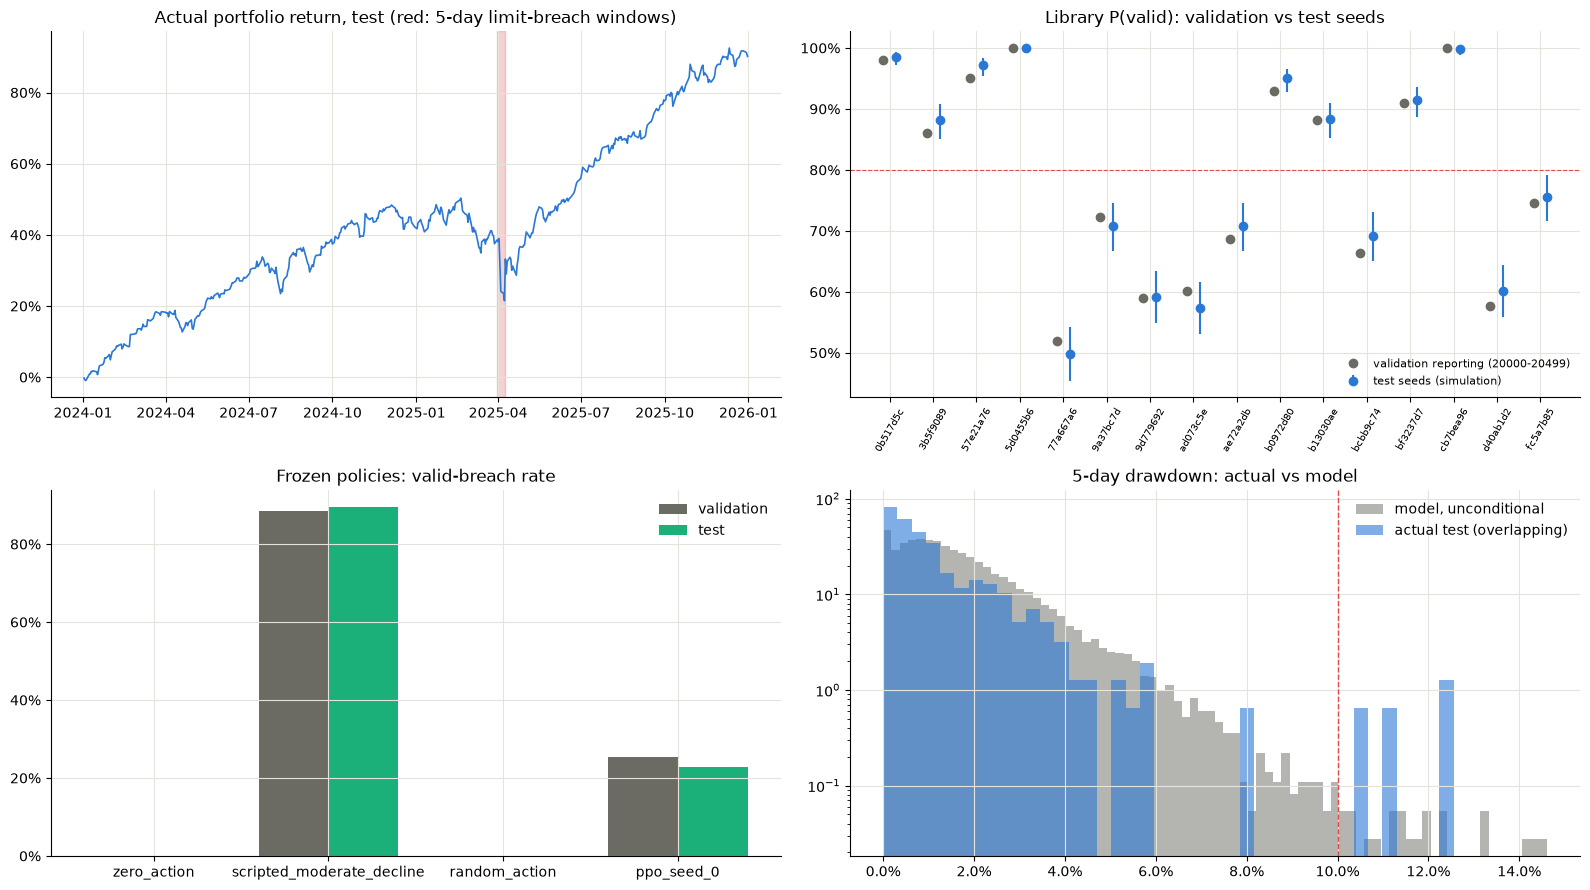

In [15]:
fig, ax = plt.subplots(2, 2, figsize=(16, 9))
vals = CAP * (1 + rp[EVAL_SPLIT]).cumprod()
ax[0, 0].plot(vals.index, vals / CAP - 1, color="#2a78d6", linewidth=1.2)
for a, b in merge_overlapping(np.flatnonzero(RWE["breached"].to_numpy()), H):
    ax[0, 0].axvspan(RWE.loc[a, "start"], RWE.loc[b, "end"], color="#e34948", alpha=0.25)
ax[0, 0].yaxis.set_major_formatter(PercentFormatter(1.0)); ax[0, 0].set_title(f"Actual portfolio return, {EVAL_SPLIT} (red: 5-day limit-breach windows)")
x = np.arange(len(SIDS))
ax[0, 1].errorbar(x - 0.15, lib_test["val reporting P(valid)"], fmt="o", color="#6b6a63", label="validation reporting (20000-20499)")
ax[0, 1].errorbar(x + 0.15, lib_test["P(valid)"], yerr=[(lib_test["P(valid)"] - lib_test["CI low"]).clip(lower=0), (lib_test["CI high"] - lib_test["P(valid)"]).clip(lower=0)], fmt="o", color="#2a78d6",
                  label=f"{EVAL_SPLIT} seeds (simulation)")
ax[0, 1].axhline(0.8, color="#e34948", linewidth=0.8, linestyle="--"); ax[0, 1].set_xticks(x, [s[3:] for s in SIDS], rotation=60, fontsize=7)
ax[0, 1].yaxis.set_major_formatter(PercentFormatter(1.0)); ax[0, 1].set_title("Library P(valid): validation vs test seeds"); ax[0, 1].legend(frameon=False, fontsize=8)
pt = policy_tbl.set_index("policy")
xx = np.arange(len(pt))
ax[1, 0].bar(xx - 0.2, pt["validation valid breach (1,500 eps)"], width=0.4, color="#6b6a63", label="validation")
ax[1, 0].bar(xx + 0.2, pt[f"{EVAL_SPLIT} valid breach"], width=0.4, color="#1baf7a", label=EVAL_SPLIT)
ax[1, 0].set_xticks(xx, pt.index); ax[1, 0].yaxis.set_major_formatter(PercentFormatter(1.0)); ax[1, 0].set_title("Frozen policies: valid-breach rate"); ax[1, 0].legend(frameon=False)
ax[1, 1].hist(sim_dd, bins=80, density=True, alpha=0.5, color="#6b6a63", label="model, unconditional")
ax[1, 1].hist(RWE["drawdown"], bins=40, density=True, alpha=0.6, color="#2a78d6", label=f"actual {EVAL_SPLIT} (overlapping)")
ax[1, 1].axvline(dd_limit, color="#e34948", linestyle="--", linewidth=1); ax[1, 1].set_yscale("log")
ax[1, 1].xaxis.set_major_formatter(PercentFormatter(1.0)); ax[1, 1].set_title("5-day drawdown: actual vs model"); ax[1, 1].legend(frameon=False)
plt.tight_layout(); plt.show()

## 12. Limitations and interpretation
The numbers in the tables above are authoritative. This text states what the design can and cannot support.
- **Scenario replay is not historical testing.** The simulator's dynamics do not use the anchor's market state, so library and recommender results on "test" seeds are new Monte Carlo draws from the same train-fitted model. They test robustness to residual randomness, not to the 2024–2025 regime. Validation-to-test differences here are sampling variation.
- **The historical evidence is the Stage 4 section and the coverage analysis.** These are the only places where actual 2024–2025 returns enter. Coverage depends on a fixed distance-and-family rule and on the discrete library, which ties SPY to QQQ and XLF to XLE.
- **Policy generalisation is tested only for PPO**, the one frozen policy with a saved checkpoint. Tabular Q-learning was not saved and is not tested. The fixed replay of its paths says nothing about its policy.
- **Dependence.** Overlapping 5-day windows are merged into episodes, and their intervals use non-overlapping windows. Daily tail and VaR-exceedance intervals treat days as independent, which volatility clustering violates, so those intervals are optimistic. With about 100 non-overlapping test windows, the historical limit-breach share is imprecise.
- **One test period.** 2024–2025 is a single regime sample. Conclusions about stability are limited to it.

## 13. Automated assertions and final integrity verification

In [16]:
checks = []
def check(name, ok, detail=""):
    checks.append({"check": name, "result": "PASS" if ok else "FAIL", "detail": str(detail)})
check("evaluation period boundaries", TEST_FIRST >= pd.Timestamp(EVAL_START) and TEST_LAST <= pd.Timestamp(EVAL_END) and N_EVAL_DAYS == split_summary[EVAL_SPLIT]["n_rows"],
      f"{TEST_FIRST.date()}..{TEST_LAST.date()}, {N_EVAL_DAYS} days")
check("no evaluation data in fitting, selection or tuning", all(leak.values()))
check("frozen artifact checksums (incl. Stage 6 library, Stage 7 output, PPO checkpoint)", bool(manifest["match"].all()))
check("full five-day paths present and unchanged", all(p.shape == (H, 4) for p in PATHS.values()) and
      hashlib.sha256(json.dumps({k: L[k]["robust_action_path"] for k in sorted(L)}).encode()).hexdigest() == PATHS_SHA and sha(LIBRARY_PATH) == FROZEN_EXPECTED["results/stage6/scenario_library.json"])
check("weights, eligibility and rankings frozen (recomputed from frozen artifacts)", ranking_reproduced and RCFG.weights == rec7["config"]["weights"])
check("policy evaluation counts", not policy_failures and all(len(r) == len(TEST_SEEDS) for r in policy_records.values()) and len(policy_records) == 4,
      f"{len(policy_records)} x {len(TEST_SEEDS)}")
check("library replay counts", not replay_failures and all(len(rep_records[s]) == len(TEST_SEEDS) for s in SIDS) and M["valid_breach"].shape == (len(TEST_SEEDS), len(SIDS)),
      f"{len(SIDS)} x {len(TEST_SEEDS)}")
check("failed / invalid episodes reported, none omitted", len(policy_tbl) + len(policy_failures) == 4 and len(lib_test) + len(replay_failures) == len(SIDS),
      f"invalid replay episodes {sum(invalid_eps.values())}; policy failures {len(policy_failures)}")
check("historical window counts consistent", all(len(RW[s]) == len(win(s)) - H + 1 for s in RW) and int(plaus_hist.set_index("period").loc[EVAL_SPLIT, "windows (overlapping)"]) == len(RW[EVAL_SPLIT]))
check("deterministic replay anchor-independent (Stage 6 values reproduced)", det_diff < 1e-9, f"{det_diff:.1e}")
again = evaluate_policy(eval_env, OpenLoopPolicy(PATHS[SIDS[0]], OBS, SIDS[0]), TEST_SEEDS[:50])
again_ppo = evaluate_policy(ppo_env, load_policy(CKPT_DIR, ppo_env, "best", name="ppo_check"), TEST_SEEDS[:20])
check("reproducible under the documented configuration (re-run replay and PPO)",
      [r.valid_breach for r in again] == [r.valid_breach for r in rep_records[SIDS[0]][:50]]
      and [r.path_drawdown for r in again_ppo] == [r.path_drawdown for r in policy_records[f"ppo_seed_{seed_sel}"][:20]])
check("Stage 3-7 results, notebooks, source and config unchanged", {k: tree_hash(v) for k, v in PROTECTED.items()} == HASH_BEFORE)
checks_df = pd.DataFrame(checks)
display(checks_df.style.hide(axis="index").map(lambda v: "color: #008300; font-weight: bold" if v == "PASS" else ("color: #e34948; font-weight: bold" if v == "FAIL" else ""), subset=["result"]))
print(f"{(checks_df['result'] == 'PASS').sum()}/{len(checks_df)} checks PASS")
assert (checks_df["result"] == "PASS").all()

check,result,detail
evaluation period boundaries,PASS,"2024-01-02..2025-12-31, 502 days"
"no evaluation data in fitting, selection or tuning",PASS,
"frozen artifact checksums (incl. Stage 6 library, Stage 7 output, PPO checkpoint)",PASS,
full five-day paths present and unchanged,PASS,
"weights, eligibility and rankings frozen (recomputed from frozen artifacts)",PASS,
policy evaluation counts,PASS,4 x 500
library replay counts,PASS,16 x 500
"failed / invalid episodes reported, none omitted",PASS,invalid replay episodes 0; policy failures 0
historical window counts consistent,PASS,
deterministic replay anchor-independent (Stage 6 values reproduced),PASS,0.0e+00


12/12 checks PASS


## 14. Export the final report and machine-readable results

In [17]:
from rlstress.scenario_library import to_json
OUT_DIR.mkdir(parents=True, exist_ok=True)
if RESULTS_PATH.exists() and not OVERWRITE:
    raise FileExistsError(RESULTS_PATH)
results = {
    "stage": 8, "schema_version": "stage8.v1", "generated_utc": pd.Timestamp.now(tz="UTC").isoformat(), "preflight": PREFLIGHT,
    "evaluation_split": EVAL_SPLIT, "period": {"configured": SPLITS[EVAL_SPLIT], "first_date": str(TEST_FIRST.date()), "last_date": str(TEST_LAST.date()), "trading_days": N_EVAL_DAYS,
                                               "anchors": len(anchors), "real_5day_windows": len(RW[EVAL_SPLIT])},
    "evidence_types": {"HISTORICAL": "actual returns through the frozen model / Stage 3 engine", "SIMULATION": "frozen paths, simulated residuals; anchor-independent dynamics",
                       "POLICY": "frozen PPO checkpoint on evaluation-period states"},
    "manifest": manifest.to_dict("records"), "protected_tree_hashes": HASH_BEFORE, "versions": VERSIONS, "frozen": frozen,
    "seeds": {"test": [TEST_SEEDS.start, TEST_SEEDS.stop - 1], "upstream": {k: [r.start, r.stop - 1] for k, r in UPSTREAM_SEEDS.items()}, "overlap": seed_overlap,
              "random_shortlists": [RANDOM_SEEDS.start, RANDOM_SEEDS.stop - 1], "model_tail_simulation": SEED, "bootstrap": SEED},
    "leakage_checks": leak,
    "stage4": {"factor_fit": fit.reset_index().to_dict("records"), "daily_tail_calibration": calib.to_dict("records"), "real_window_plausibility": plaus_hist.to_dict("records"),
               "simulated_vs_actual_stocks": sve.to_dict("records"), "simulated_vs_actual_portfolio": sve_port, "var_backtest": var_bt.to_dict("records"),
               "portfolio_performance": perf.to_dict("records"), "five_day_limits": limit_hist.to_dict("records"), "five_day_tail": tail_tbl.to_dict("records")},
    "stage5": {"policy_checkpoint": {"path": str(CKPT_DIR.relative_to(PROJECT_ROOT)), "sha256": FROZEN_EXPECTED[str((CKPT_DIR / "best_model.zip").relative_to(PROJECT_ROOT))],
                                     "threshold": q_sel, "seed": seed_sel, "deterministic": True},
               "policies": policy_tbl.to_dict("records"), "ppo_diversity": ppo_div, "failures": policy_failures,
               "q_learning_policy": "not evaluated: Q-tables were not saved; retraining is not permitted",
               "scenario_replay_by_method": by_method.reset_index().to_dict("records")},
    "stage6": {"per_scenario": lib_test.reset_index().to_dict("records"), "deterministic_anchor_check_max_diff": det_diff, "failures": replay_failures,
               "historical_coverage": cov_lib.to_dict("records"), "coverage_rule": f"nearest scenario distance <= {TAU} and same family; targets: breach episodes + 5 worst distinct weeks"},
    "stage7": {"per_recommender": rec_tbl.reset_index().to_dict("records"), "paired_differences": pairs_tbl.to_dict("records"), "diversity_frozen": div_frozen.reset_index().to_dict("records"),
               "stability": stability, "shortlists": {"highest_score": TOP_IDS, "diversity_aware": DIV_IDS}},
    "validation_vs_test": vt.to_dict("records"), "checks": checks_df.to_dict("records"),
    "runtime_seconds": {"policies": ppo_runtime, "replay": replay_runtime},
}
import datetime as _dt
def iso_dates(x):
    if isinstance(x, dict):
        return {(k.isoformat() if isinstance(k, (_dt.date, pd.Timestamp)) else k): iso_dates(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [iso_dates(v) for v in x]
    return x.isoformat() if isinstance(x, (_dt.date, pd.Timestamp)) else x
results = iso_dates(results)
RESULTS_PATH.write_text(to_json(results))
(OUT_DIR / "manifest.json").write_text(to_json({"manifest": results["manifest"], "protected_tree_hashes": HASH_BEFORE, "versions": VERSIONS}))
lib_test.drop(columns=[]).to_csv(OUT_DIR / "per_scenario.csv")
rec_tbl.to_csv(OUT_DIR / "per_recommender.csv")
policy_tbl.to_csv(OUT_DIR / "policies.csv", index=False)
vt.to_csv(OUT_DIR / "validation_vs_test.csv", index=False)
def md_table(df, digits=4):
    df = df.copy()
    cells = [[(f"{v:.{digits}f}" if isinstance(v, (float, np.floating)) else str(v)) for v in row] for row in df.astype(object).itertuples(index=False)]
    head = [str(c) for c in df.columns]
    return "\n".join(["| " + " | ".join(head) + " |", "|" + "---|" * len(head)] + ["| " + " | ".join(r) + " |" for r in cells])
report = ["# Stage 8 — final out-of-sample evaluation" + (" (PREFLIGHT, not a test result)" if PREFLIGHT else ""), "",
          f"Evaluation split **{EVAL_SPLIT}**: {TEST_FIRST.date()} – {TEST_LAST.date()}, {N_EVAL_DAYS} trading days, {len(anchors)} anchors, "
          f"{len(RW[EVAL_SPLIT])} actual 5-day windows; seeds {TEST_SEEDS.start}–{TEST_SEEDS.stop - 1}.", "",
          "Evidence types: HISTORICAL (actual returns), SIMULATION (frozen paths, simulated residuals; anchor-independent), POLICY (frozen PPO).", "",
          "## Validation vs test", "", md_table(vt), "",
          "## Frozen policies", "", md_table(policy_tbl), "",
          "## Recommenders", "", md_table(rec_tbl.reset_index()), "",
          "## Historical coverage of actual stress weeks", "", md_table(cov_lib), "",
          "## Checks", "", md_table(checks_df), "",
          "## Limitations", "",
          "- Scenario replay is simulation (anchor-independent dynamics), not historical testing; only PPO policy generalisation is tested; "
          "Q-learning tables were not saved; daily intervals ignore volatility clustering; one two-year test regime."]
(OUT_DIR / "final_test_report.md").write_text("\n".join(report))
print("Wrote to", OUT_DIR, *sorted(p.name for p in OUT_DIR.iterdir()), sep="\n  ")

Wrote to
  RS-RL/results/stage8
  final_test_report.md
  final_test_results.json
  manifest.json
  per_recommender.csv
  per_scenario.csv
  policies.csv
  validation_vs_test.csv
